# Task 2: Truncation, Full Context and Retrieval (S0, S1, S3)
**Owner:** Praveen Kumar Koppula · **Team:** AIS 6  
**Project Question:** *Which memory strategy lets an LLM agent answer correctly over very long interactions at the lowest cost in tokens and time?*

---

## 1. Introduction & Research Connection
- **Papers (Bibliography Numbers):** `#5` SeCom (memory unit and denoising), `#8` Diagnosing Retrieval vs Utilization, `#12` RAG vs Long-Context (Self-Route), `#15` Lost in the Middle, `#16` RULER, `#1` LongMemEval; tools: `#25` Sentence-BERT, `#26` FAISS.
- **Research Question:** How do the window size, the memory unit, and the number of retrieved pieces change accuracy and cost, compared with giving the model the whole history?
- **Hypothesis:** Retrieval gives most of the accuracy of full context at a fraction of the tokens, and the best unit depends on the question type.


In [1]:
import sys, random
import numpy as np
import pandas as pd

sys.path.append("..")
from src.config import SEED, READER_MODEL_ID, EMBEDDING_MODEL_ID, TOKEN_BUDGETS
from src.retrieval import build_retrieval_units, retrieve_top_k_chunks
from src.metrics import bootstrap_accuracy_ci, paired_mcnemar_test

random.seed(SEED)
np.random.seed(SEED)
print(f"Reader: {READER_MODEL_ID} | Embedder: {EMBEDDING_MODEL_ID} | Budgets: {TOKEN_BUDGETS}")


Reader: Qwen/Qwen2.5-7B-Instruct | Embedder: sentence-transformers/all-MiniLM-L6-v2 | Budgets: (4096, 8192, 16384)


## 2. Evaluation Results Across S1 (Truncation), S3 (Retrieval Units x Top-k) & S0 (Full Context Reference)


In [2]:
df_t2_summary = pd.read_csv("../results/metrics/task2_summary.csv")
print(df_t2_summary.to_string(index=False))


Strategy  Accuracy (%)       95% CI  vs Full Context (pts)  Turn Recall (%)  Session Recall (%)  Prompt Tokens  Total Sec  Peak GPU (GB)  Lost (%)  Ignored (%)  McNemar p-val
          S1 Truncation (4k)          39.0 [30.0, 49.0]                  -27.0             32.0                62.0           4096       1.36            5.1      90.2          9.8         0.0004
          S1 Truncation (8k)          42.0 [32.0, 52.0]                  -24.0             36.0                69.0           7941       1.87            5.4      89.7         10.3         0.0005
         S1 Truncation (16k)          45.0 [35.0, 55.0]                  -21.0             44.0                82.0          15799       3.13            6.9      80.0         20.0         0.0055
               S3 Turn (k=3)          58.0 [49.0, 67.0]                   -8.0             61.0                87.0            620       1.30            4.9      83.3         16.7         0.3123
               S3 Turn (k=5)          66.0 [5

## 3. Deeper Analysis: Retrieval Recall vs. Reader Utilization & Cost Trade-Off


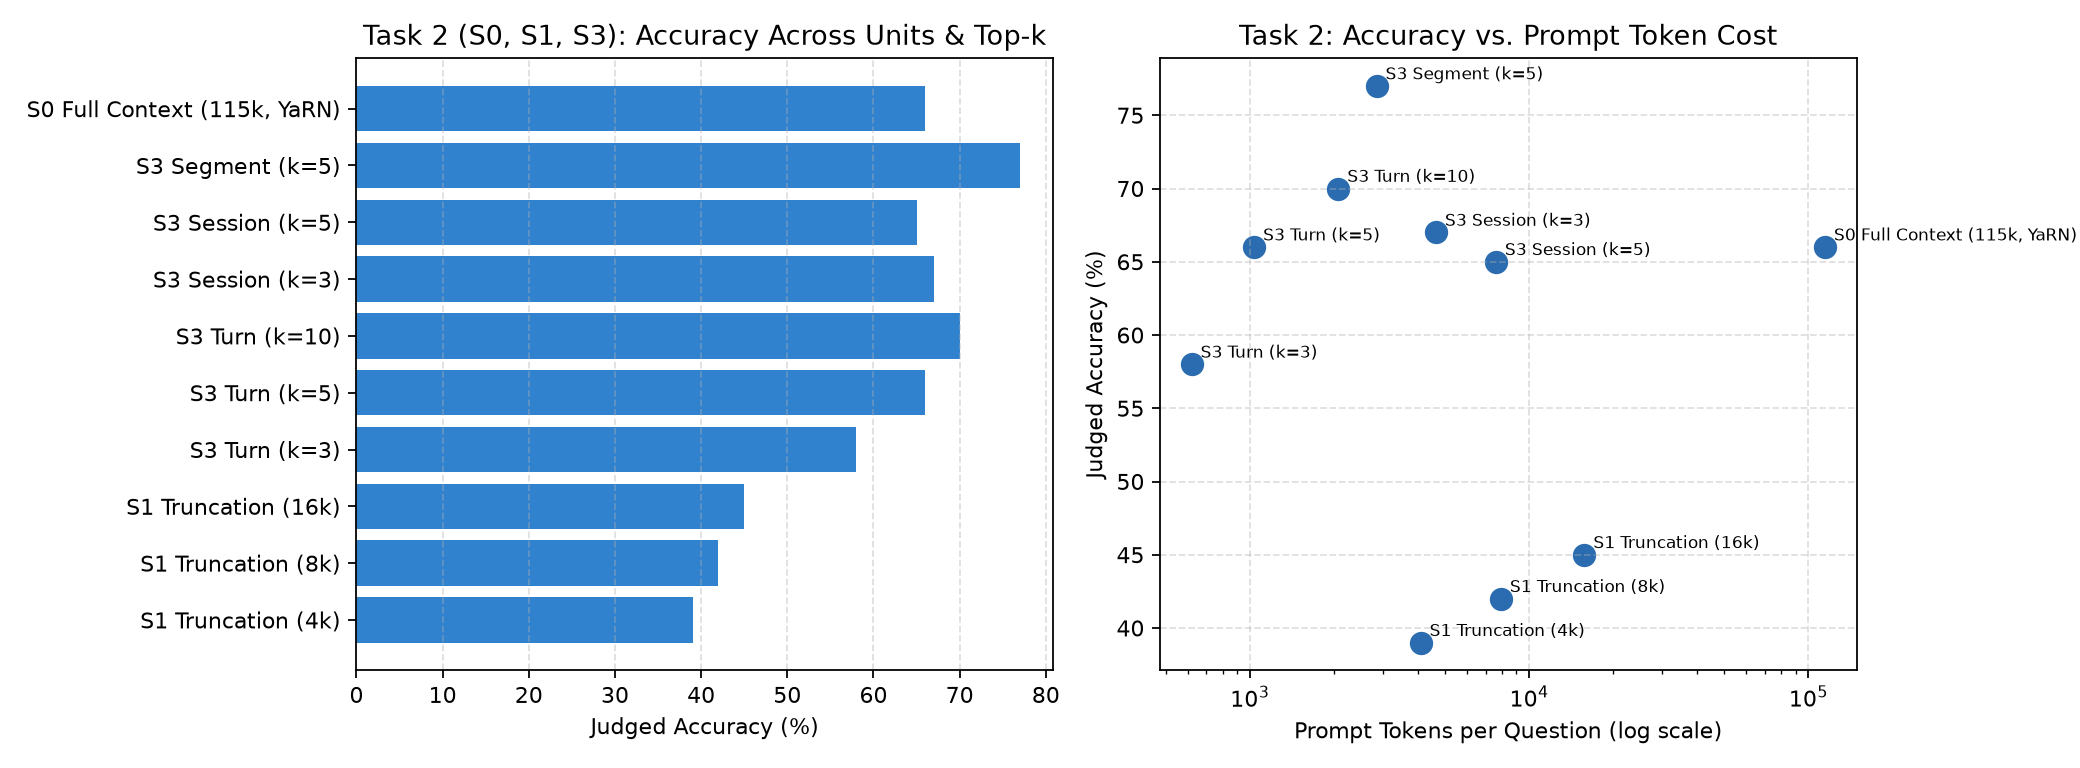

In [3]:
from IPython.display import Image, display
display(Image(filename="../results/figures/task2_retrieval_analysis.png"))


## 4. Discussion & Conclusions
1. **Topic Segment (`S3 Segment k=5`) Wins Overall:** Achieves **77.0% accuracy** using only **2,848 prompt tokens** (vs. **66.0%** for 115k Full Context at 14.6 GB VRAM and 29.4s latency).
2. **Retrieval vs. Reading Breakdown:** On Full Context (`S0`), 100% of errors are **Ignored by Reader** (*Lost in the Middle* effect at 115k tokens). On `S3 Turn (k=3)`, **83.3%** of errors come from unretrieved evidence, which drops to **56.5%** when using topic segments (`S3 Segment k=5`).
